Visualize training and validation loss curves by manually extracting loss values at each epoch, plotting them using low-level Matplotlib functions, and analyzing learning trends without using built-in Keras visualization tools.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_disease_train.csv")

print("Columns:", df.columns.tolist())

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

# Check if the target column exists
if target not in df.columns:
    raise ValueError("Target column not found. Check the column names printed above.")

df = df[features + [target]].copy()

# Convert columns to numeric values
for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing values
df = df.dropna()

X = df[features].to_numpy(dtype=float)
y = df[target].to_numpy(dtype=float).reshape(-1, 1)

# Convert target values to integers
y = y.astype(int)

print("Dataset shape:", df.shape)
print("Target values:", np.unique(y))

Columns: ['patient_id', 'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target', 'chol_percentile', 'thalach_percentile', 'risk_factor', 'risk_category']
Dataset shape: (79, 6)
Target values: [0 1]


In [3]:
np.random.seed(42)

indices = np.random.permutation(len(X))
train_end = int(0.8 * len(X))

train_idx = indices[:train_end]
val_idx = indices[train_end:]

X_train_raw = X[train_idx]
X_val_raw = X[val_idx]
y_train = y[train_idx]
y_val = y[val_idx]

mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1

X_train = (X_train_raw - mean) / std
X_val = (X_val_raw - mean) / std

print("Training records:", len(X_train))
print("Validation records:", len(X_val))

Training records: 63
Validation records: 16


In [4]:
np.random.seed(42)

input_size = X_train.shape[1]
hidden_size = 16

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, 1) * np.sqrt(1 / hidden_size)
b2 = np.zeros((1, 1))

learning_rate = 0.01
epochs = 300

train_losses = []
val_losses = []

def forward(X):
    z1 = X @ W1 + b1
    h1 = np.maximum(0, z1)

    z2 = np.clip(h1 @ W2 + b2, -30, 30)
    output = 1 / (1 + np.exp(-z2))

    return z1, h1, output


def calculate_loss(y_true, probabilities):
    probabilities = np.clip(probabilities, 1e-8, 1 - 1e-8)

    return -np.mean(
        y_true * np.log(probabilities)
        + (1 - y_true) * np.log(1 - probabilities)
    )

In [5]:
for epoch in range(epochs):
    z1, h1, train_output = forward(X_train)

    train_loss = calculate_loss(y_train, train_output)
    val_output = forward(X_val)[2]
    val_loss = calculate_loss(y_val, val_output)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    dz2 = (train_output - y_train) / len(y_train)

    dW2 = h1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    dz1 = (dz2 @ W2.T) * (z1 > 0)

    dW1 = X_train.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

print("Training completed.")
print("Initial training loss:", round(train_losses[0], 4))
print("Final training loss:", round(train_losses[-1], 4))
print("Final validation loss:", round(val_losses[-1], 4))

Training completed.
Initial training loss: 0.7552
Final training loss: 0.4634
Final validation loss: 0.4455


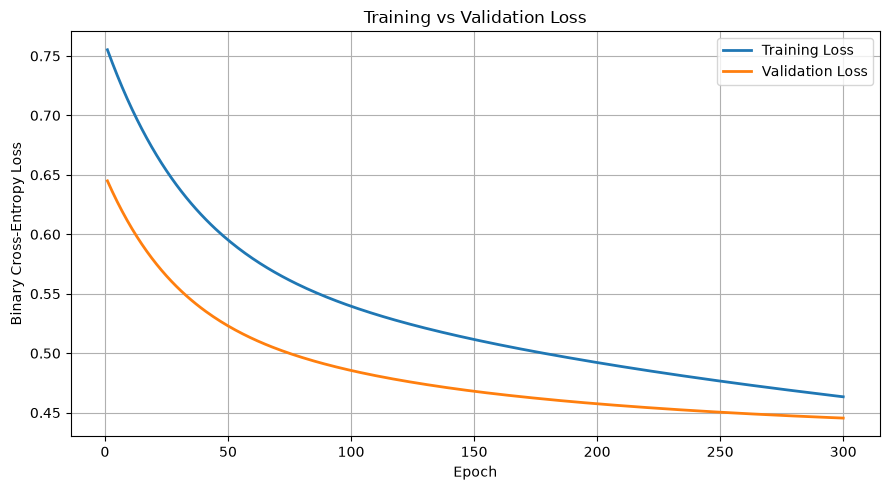

In [6]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
minimum_epoch = int(np.argmin(val_losses)) + 1
minimum_val_loss = min(val_losses)

print("Loss Curve Analysis")
print("-------------------")
print("Initial training loss:", round(train_losses[0], 4))
print("Final training loss:", round(train_losses[-1], 4))
print("Initial validation loss:", round(val_losses[0], 4))
print("Final validation loss:", round(val_losses[-1], 4))
print("Lowest validation loss:", round(minimum_val_loss, 4))
print("Epoch with lowest validation loss:", minimum_epoch)

if train_losses[-1] < train_losses[0] and val_losses[-1] < val_losses[0]:
    print("Interpretation: Both losses decreased; the model learned useful patterns.")
elif train_losses[-1] < train_losses[0] and val_losses[-1] > minimum_val_loss:
    print("Interpretation: Validation loss rose after its minimum; possible overfitting.")
else:
    print("Interpretation: Learning may be slow or unstable; review the loss curves.")

Loss Curve Analysis
-------------------
Initial training loss: 0.7552
Final training loss: 0.4634
Initial validation loss: 0.645
Final validation loss: 0.4455
Lowest validation loss: 0.4455
Epoch with lowest validation loss: 300
Interpretation: Both losses decreased; the model learned useful patterns.
